<div align="center">

<a href="https://colab.research.google.com/github/YOUR_USERNAME/YOUR_REPO/blob/main/MID2_standard_to_controller.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Midterm option 2: From a standard to a controller
## Li-ion cell charging: a JEITA rule base and a fuzzy charge-current controller

**Artificial Intelligence Applications in Engineering (MUH-920 Mühendislikte Yapay Zeka Uygulamaları)**<br>Midterm project: Search, knowledge and optimisation in practice<br>Course: Prof. Dr. Utku Kose, Süleyman Demirel University<br>Starter notebook: [utkukose/ai-applications-in-engineering-NB-lecture](https://github.com/utkukose/ai-applications-in-engineering-NB-lecture) (content CC BY 4.0, code MIT)

**Team:** NAME SURNAME (Electrical-Electronics Eng.) · NAME SURNAME (Electrical-Electronics Eng.) · NAME SURNAME (Chemical Eng.)

</div>

## 0. Project summary

**Topic: safe and gentle charging of a lithium-ion battery cell.** The team is two electrical-electronics engineers and one chemical engineer.

| Part | What we build | Knowledge source | Technique |
|---|---|---|---|
| 1-2 | A charging-safety and health check that a battery management system (BMS) runs before and during charging | JEITA/BAJ safety guide for Li-ion charging, cell datasheet limits, common end-of-life criteria | Rule base (dictionaries), forward chaining, backward chaining (`prove`), explanation |
| 3-4 | A charge-current controller | Electrochemistry of lithium plating and SEI growth | Two-input Mamdani fuzzy controller, compared with CC-CV + on-off thermostat and with the crisp JEITA step charger from Part 1 |

Why this topic fits the team: the charger, the current control and the equivalent circuit model are electrical engineering. *Why* the current must change with temperature is electrochemistry. At low temperature lithium plates on the graphite anode. At high temperature the solid-electrolyte interphase (SEI) grows faster.

The notebook is self-contained and needs only `numpy` and `matplotlib`. In Colab, use *Runtime → Run all*. The full run takes under a minute.

In [1]:
import math
import os

import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9})
print("numpy", np.__version__)

numpy 2.5.3


## 1. The rule base

A BMS measures numbers, while rules reason with symbols. The knowledge base therefore has two layers:

1. **Sensing layer, `sense()`.** It turns measurements into symbolic facts using the thresholds of the sources, for example `T = 7.5` becomes `"0 <= T < 10 C"`. Each threshold appears exactly once, in this function.
2. **Rules.** A list of dictionaries in the Week 3 format: `name`, `if` (all conditions must hold), `then` and `source`.

**Measurements** (per cell, or the worst cell of a pack):
`T` cell temperature [°C], `V` cell voltage [V], `dTdt` temperature rise rate [°C/min], `SOH` capacity / rated capacity, `R_ratio` internal resistance / resistance when new, `spread` voltage difference between the highest and lowest series cell [V].

**Sources**
* **[JEITA]** JEITA & BAJ, *A Guide to the Safe Use of Secondary Lithium Ion Batteries in Notebook-type Personal Computers*, 2007. These are the temperature zones for charging. We use the zone values that typical charger ICs use: T1 = 0, T2 = 10, T3 = 45, T4 = 60 °C. Current is halved in the cool zone, and the voltage limit is lowered to 4.10 V in the warm zone.
* **[DS]** A typical NMC 18650 cell datasheet: maximum charge voltage 4.20 V, discharge cut-off 2.50 V, standard charge 1C.
* **[IEC 62133-2]** The charger must keep the cell within the upper charge voltage and temperature limits given by the cell manufacturer.
* **[EOL]** The common end-of-first-life criterion is 80 % of rated capacity (used, for example, in USABC test manuals). Packs between 80 and 60 % are considered for second-life use.
* **[EXP]** Engineering heuristics. These must be reviewed by an expert (see Section 5).

In [2]:
# ---------------------------------------------------------------- sensing
V_MAX, V_OV, V_MIN = 4.20, 4.25, 2.50     # [DS] charge limit, overvoltage, cut-off


def sense(m):
    """Measurements (dict of numbers) -> set of symbolic facts."""
    f = set()
    T, V = m["T"], m["V"]
    # temperature zones [JEITA]
    if T < 0:
        f.add("T < 0 C")
    elif T < 10:
        f.add("0 <= T < 10 C")
    elif T < 45:
        f.add("10 <= T < 45 C")
    elif T < 60:
        f.add("45 <= T < 60 C")
    else:
        f.add("T >= 60 C")
    # voltage window [DS]
    if V > V_OV:
        f.add("V > 4.25 V")
    elif V < V_MIN:
        f.add("V < 2.50 V")
    else:
        f.add("2.50 <= V <= 4.25 V")
    # self-heating [EXP]
    f.add("dT/dt > 1 C/min" if m["dTdt"] > 1.0 else "dT/dt <= 1 C/min")
    # capacity [EOL]
    if m["SOH"] >= 0.8:
        f.add("SOH >= 80 %")
    elif m["SOH"] >= 0.6:
        f.add("60 % <= SOH < 80 %")
    else:
        f.add("SOH < 60 %")
    # resistance growth [EXP]
    f.add("R/R_new > 2" if m["R_ratio"] > 2.0 else "R/R_new <= 2")
    # series-cell imbalance [EXP]
    f.add("cell spread > 50 mV" if m["spread"] > 0.050 else
          "cell spread <= 50 mV")
    return f


SENSOR_FACTS = {"T < 0 C", "0 <= T < 10 C", "10 <= T < 45 C", "45 <= T < 60 C",
                "T >= 60 C", "V > 4.25 V", "V < 2.50 V", "2.50 <= V <= 4.25 V",
                "dT/dt > 1 C/min", "dT/dt <= 1 C/min", "SOH >= 80 %",
                "60 % <= SOH < 80 %", "SOH < 60 %", "R/R_new > 2",
                "R/R_new <= 2", "cell spread > 50 mV", "cell spread <= 50 mV"}

In [3]:
DS, JEITA, IEC, EOL, EXP = ("[DS] cell datasheet", "[JEITA] safety guide 2007",
                            "[IEC 62133-2] charge within manufacturer limits",
                            "[EOL] 80 % capacity end of first life",
                            "[EXP] engineering heuristic")

RULES = [
    # --- A. safety faults ---------------------------------------------------
    {"name": "R1", "if": ["V > 4.25 V"], "then": "fault: overvoltage", "source": DS},
    {"name": "R2", "if": ["V < 2.50 V"], "then": "fault: deep discharge", "source": DS},
    {"name": "R3", "if": ["T >= 60 C"], "then": "fault: overtemperature", "source": JEITA},
    {"name": "R4", "if": ["dT/dt > 1 C/min"], "then": "fault: abnormal self-heating", "source": EXP},
    {"name": "R5", "if": ["fault: overvoltage"], "then": "charging forbidden", "source": IEC},
    {"name": "R6", "if": ["fault: overtemperature"], "then": "charging forbidden", "source": JEITA},
    {"name": "R7", "if": ["fault: abnormal self-heating"], "then": "charging forbidden", "source": EXP},
    {"name": "R8", "if": ["T < 0 C"], "then": "charging forbidden", "source": JEITA},
    # --- B. JEITA charge mode (only when the cell is electrically sound) ----
    {"name": "R9", "if": ["2.50 <= V <= 4.25 V", "dT/dt <= 1 C/min"],
     "then": "cell within safe window", "source": IEC},
    {"name": "R10", "if": ["cell within safe window", "0 <= T < 10 C"],
     "then": "mode: cool charge (I <= 0.5C, V <= 4.20 V)", "source": JEITA},
    {"name": "R11", "if": ["cell within safe window", "10 <= T < 45 C"],
     "then": "mode: standard charge (I <= 1C, V <= 4.20 V)", "source": JEITA},
    {"name": "R12", "if": ["cell within safe window", "45 <= T < 60 C"],
     "then": "mode: warm charge (I <= 1C, V <= 4.10 V)", "source": JEITA},
    {"name": "R13", "if": ["fault: deep discharge", "dT/dt <= 1 C/min", "10 <= T < 45 C"],
     "then": "mode: pre-charge (I <= 0.1C until V > 3.0 V)", "source": DS},
    {"name": "R14", "if": ["fault: deep discharge", "dT/dt <= 1 C/min", "0 <= T < 10 C"],
     "then": "mode: pre-charge (I <= 0.1C until V > 3.0 V)", "source": DS},
    {"name": "R15", "if": ["fault: deep discharge", "45 <= T < 60 C"],
     "then": "charging forbidden", "source": DS},
    # --- C. state of health -------------------------------------------------
    {"name": "R16", "if": ["SOH >= 80 %", "R/R_new <= 2"], "then": "health: good", "source": EOL},
    {"name": "R17", "if": ["60 % <= SOH < 80 %"], "then": "health: second-life", "source": EOL},
    {"name": "R18", "if": ["SOH < 60 %"], "then": "health: end of life", "source": EOL},
    {"name": "R19", "if": ["R/R_new > 2"], "then": "health: high resistance", "source": EXP},
    # --- D. actions -----------------------------------------------------------
    {"name": "R20", "if": ["charging forbidden"],
     "then": "action: stop charger and alarm", "source": IEC},
    {"name": "R21", "if": ["fault: abnormal self-heating"],
     "then": "action: isolate pack, possible thermal runaway", "source": EXP},
    {"name": "R22", "if": ["fault: overvoltage"],
     "then": "action: check charger voltage regulation", "source": EXP},
    {"name": "R23", "if": ["cell spread > 50 mV"],
     "then": "action: balance cells", "source": EXP},
    {"name": "R24", "if": ["health: end of life"],
     "then": "action: replace pack", "source": EOL},
    {"name": "R25", "if": ["health: second-life"],
     "then": "action: plan replacement, derate current to 0.5C", "source": EOL},
    {"name": "R26", "if": ["health: high resistance"],
     "then": "action: plan replacement, derate current to 0.5C", "source": EXP},
    {"name": "R27", "if": ["mode: standard charge (I <= 1C, V <= 4.20 V)", "health: good"],
     "then": "action: charge normally", "source": JEITA},
]

# priority used to pick ONE charge decision when several were derived
MODE_PRIORITY = ["charging forbidden",
                 "mode: pre-charge (I <= 0.1C until V > 3.0 V)",
                 "mode: cool charge (I <= 0.5C, V <= 4.20 V)",
                 "mode: warm charge (I <= 1C, V <= 4.10 V)",
                 "mode: standard charge (I <= 1C, V <= 4.20 V)"]

print(len(RULES), "rules")

27 rules


**Consistency check of the knowledge base.** Every condition must be a sensor fact or the conclusion of some rule. This catches typos, which are the most common bug in hand-written rule bases.

In [4]:
conclusions = {r["then"] for r in RULES}
problems = [(r["name"], c) for r in RULES for c in r["if"]
            if c not in SENSOR_FACTS and c not in conclusions]
names = [r["name"] for r in RULES]
assert len(names) == len(set(names)), "duplicate rule names"
print("unreachable conditions:", problems or "none")
print("sources used:", sorted({r["source"] for r in RULES}))

unreachable conditions: none
sources used: ['[DS] cell datasheet', '[EOL] 80 % capacity end of first life', '[EXP] engineering heuristic', '[IEC 62133-2] charge within manufacturer limits', '[JEITA] safety guide 2007']


## 2. Inference and explanation

The interface is the same as in Week 3:
* `forward_chain(facts, rules)` is data driven. It fires every rule whose conditions hold until nothing new can be derived, and returns the facts plus a trace.
* `prove(goal, facts, rules)` is goal driven (backward chaining). It returns whether the goal follows from the facts, together with the proof tree.

For the explanation facility we add `explain_how` (the trace with sources) and `why_not` (which conditions are missing for a goal).

*If your Week 3 functions differ in name or signature, paste them in place of these. The rule format is the same.*

In [5]:
def forward_chain(facts, rules):
    """Data-driven inference. Returns (all facts, trace of fired rules)."""
    facts = set(facts)
    trace = []
    changed = True
    while changed:
        changed = False
        for r in rules:
            if r["then"] not in facts and all(c in facts for c in r["if"]):
                facts.add(r["then"])
                trace.append(r)
                changed = True
    return facts, trace


def prove(goal, facts, rules, depth=0, stack=()):
    """Goal-driven inference (depth-first backward chaining).
    Returns (proved, list of lines of the proof tree)."""
    pad = "    " * depth
    if goal in facts:
        return True, [f"{pad}{goal}   <- measured"]
    if goal in stack:                      # avoid circular reasoning
        return False, []
    for r in rules:
        if r["then"] != goal:
            continue
        lines = [f"{pad}{goal}   <- {r['name']} ({r['source']})"]
        ok = True
        for c in r["if"]:
            sub_ok, sub_lines = prove(c, facts, rules, depth + 1, stack + (goal,))
            lines += sub_lines
            if not sub_ok:
                ok = False
                break
        if ok:
            return True, lines
    return False, [f"{pad}{goal}   <- cannot be proved"]


def explain_how(trace):
    return "\n".join(f"  {r['name']:4s} IF {' AND '.join(r['if'])}\n"
                     f"       THEN {r['then']}   [{r['source']}]" for r in trace)


def why_not(goal, facts, rules):
    """For every rule that could conclude `goal`, list the missing conditions."""
    out = []
    for r in rules:
        if r["then"] == goal:
            missing = [c for c in r["if"] if c not in facts]
            out.append(f"  {r['name']}: missing {missing}" if missing
                       else f"  {r['name']}: all conditions hold")
    return "\n".join(out) or f"  no rule concludes '{goal}'"


def check(m, title=""):
    """Run the whole knowledge base on one measurement and print a report."""
    obs = sense(m)
    facts, trace = forward_chain(obs, RULES)
    decision = next((d for d in MODE_PRIORITY if d in facts), "no charge mode derived")
    print(f"=== {title} ===")
    print("measured :", ", ".join(f"{k}={v}" for k, v in m.items()))
    print("observed :", sorted(obs))
    print("DECISION :", decision)
    for f in sorted(facts):
        if f.startswith(("health:", "action:", "fault:")):
            print("          ", f)
    print("HOW (forward-chaining trace):")
    print(explain_how(trace))
    return obs, facts

### Test case 1: a healthy cell at room temperature

In [6]:
case1 = {"T": 24.0, "V": 3.78, "dTdt": 0.2, "SOH": 0.93, "R_ratio": 1.2, "spread": 0.012}
obs1, facts1 = check(case1, "healthy cell, 24 C")
ok, tree = prove("action: charge normally", obs1, RULES)
print("\nprove('action: charge normally') ->", ok)
print("\n".join(tree))

=== healthy cell, 24 C ===
measured : T=24.0, V=3.78, dTdt=0.2, SOH=0.93, R_ratio=1.2, spread=0.012
observed : ['10 <= T < 45 C', '2.50 <= V <= 4.25 V', 'R/R_new <= 2', 'SOH >= 80 %', 'cell spread <= 50 mV', 'dT/dt <= 1 C/min']
DECISION : mode: standard charge (I <= 1C, V <= 4.20 V)
           action: charge normally
           health: good
HOW (forward-chaining trace):
  R9   IF 2.50 <= V <= 4.25 V AND dT/dt <= 1 C/min
       THEN cell within safe window   [[IEC 62133-2] charge within manufacturer limits]
  R11  IF cell within safe window AND 10 <= T < 45 C
       THEN mode: standard charge (I <= 1C, V <= 4.20 V)   [[JEITA] safety guide 2007]
  R16  IF SOH >= 80 % AND R/R_new <= 2
       THEN health: good   [[EOL] 80 % capacity end of first life]
  R27  IF mode: standard charge (I <= 1C, V <= 4.20 V) AND health: good
       THEN action: charge normally   [[JEITA] safety guide 2007]

prove('action: charge normally') -> True
action: charge normally   <- R27 ([JEITA] safety guide 2007)
 

### Test case 2: a warm, ageing pack that suddenly heats up
The cell is in the JEITA warm zone, where charging at a reduced voltage would normally be allowed. But it heats up at 1.8 °C/min, so rule R4 fires and charging is forbidden. Backward chaining shows the chain that leads to *isolate pack*. `why_not` shows why the warm-charge mode was **not** chosen.

In [7]:
case2 = {"T": 52.0, "V": 4.12, "dTdt": 1.8, "SOH": 0.74, "R_ratio": 1.6, "spread": 0.065}
obs2, facts2 = check(case2, "warm, ageing pack, fast self-heating")
ok, tree = prove("action: isolate pack, possible thermal runaway", obs2, RULES)
print("\nprove('action: isolate pack ...') ->", ok)
print("\n".join(tree))
print("\nwhy not 'mode: warm charge'?")
print(why_not("mode: warm charge (I <= 1C, V <= 4.10 V)", facts2, RULES))

=== warm, ageing pack, fast self-heating ===
measured : T=52.0, V=4.12, dTdt=1.8, SOH=0.74, R_ratio=1.6, spread=0.065
observed : ['2.50 <= V <= 4.25 V', '45 <= T < 60 C', '60 % <= SOH < 80 %', 'R/R_new <= 2', 'cell spread > 50 mV', 'dT/dt > 1 C/min']
DECISION : charging forbidden
           action: balance cells
           action: isolate pack, possible thermal runaway
           action: plan replacement, derate current to 0.5C
           action: stop charger and alarm
           fault: abnormal self-heating
           health: second-life
HOW (forward-chaining trace):
  R4   IF dT/dt > 1 C/min
       THEN fault: abnormal self-heating   [[EXP] engineering heuristic]
  R7   IF fault: abnormal self-heating
       THEN charging forbidden   [[EXP] engineering heuristic]
  R17  IF 60 % <= SOH < 80 %
       THEN health: second-life   [[EOL] 80 % capacity end of first life]
  R20  IF charging forbidden
       THEN action: stop charger and alarm   [[IEC 62133-2] charge within manufacturer limit

### Test case 3: borderline, 9.9 °C versus 10.1 °C
Two measurements that differ by only 0.2 °C get different charge modes. The allowed current doubles from 0.5C to 1C. This is the price of crisp thresholds, and it is the reason for the fuzzy controller in Part 3. The same cliff appears for health: SOH 79.9 % and 80.1 % give different maintenance actions.

In [8]:
for T, soh in ((9.9, 0.799), (10.1, 0.801)):
    m = {"T": T, "V": 3.70, "dTdt": 0.1, "SOH": soh, "R_ratio": 1.4, "spread": 0.02}
    facts, _ = forward_chain(sense(m), RULES)
    decision = next(d for d in MODE_PRIORITY if d in facts)
    actions = sorted(f for f in facts if f.startswith(("health", "action")))
    print(f"T = {T:4.1f} C, SOH = {soh:.3f} ->  {decision}\n{'':28s}{actions}")
m = {"T": 9.9, "V": 3.70, "dTdt": 0.1, "SOH": 0.799, "R_ratio": 1.4, "spread": 0.02}
print("\nwhy not standard charge at 9.9 C?")
print(why_not("mode: standard charge (I <= 1C, V <= 4.20 V)",
              forward_chain(sense(m), RULES)[0], RULES))

T =  9.9 C, SOH = 0.799 ->  mode: cool charge (I <= 0.5C, V <= 4.20 V)
                            ['action: plan replacement, derate current to 0.5C', 'health: second-life']
T = 10.1 C, SOH = 0.801 ->  mode: standard charge (I <= 1C, V <= 4.20 V)
                            ['action: charge normally', 'health: good']

why not standard charge at 9.9 C?
  R11: missing ['10 <= T < 45 C']


### Decision map
Here the rule base is run on a grid of temperature and voltage values, using the healthy-cell values of case 1 for the other measurements. The map shows where each decision applies and how sharp the borders are.

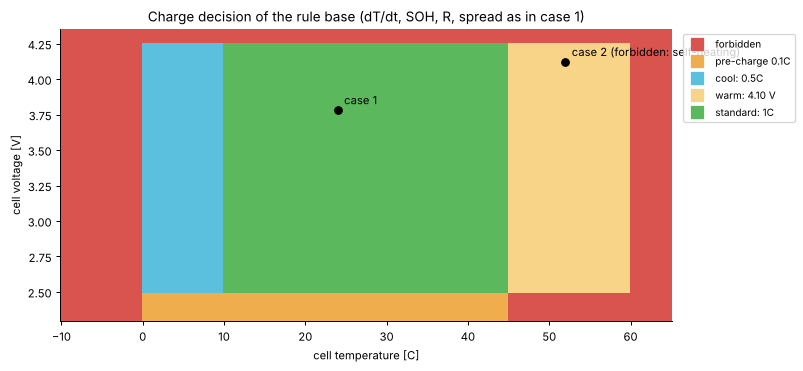

In [9]:
MODE_SHORT = {MODE_PRIORITY[0]: ("forbidden", "#d9534f"),
              MODE_PRIORITY[1]: ("pre-charge 0.1C", "#f0ad4e"),
              MODE_PRIORITY[2]: ("cool: 0.5C", "#5bc0de"),
              MODE_PRIORITY[3]: ("warm: 4.10 V", "#f7d488"),
              MODE_PRIORITY[4]: ("standard: 1C", "#5cb85c")}
Ts = np.linspace(-10, 65, 301)
Vs = np.linspace(2.3, 4.35, 206)
codes = np.zeros((len(Vs), len(Ts)))
for i, V in enumerate(Vs):
    for j, T in enumerate(Ts):
        facts, _ = forward_chain(sense({"T": T, "V": V, "dTdt": 0.2, "SOH": 0.93,
                                        "R_ratio": 1.2, "spread": 0.01}), RULES)
        codes[i, j] = next(k for k, d in enumerate(MODE_PRIORITY) if d in facts)
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.pcolormesh(Ts, Vs, codes, cmap=ListedColormap([c for _, c in MODE_SHORT.values()]),
              vmin=-0.5, vmax=4.5, shading="auto")
for k, (lab, col) in enumerate(MODE_SHORT.values()):
    ax.plot([], [], "s", color=col, ms=10, label=lab)
for m, lab in ((case1, "case 1"), (case2, "case 2 (forbidden: self-heating)")):
    ax.plot(m["T"], m["V"], "ko")
    ax.annotate(lab, (m["T"], m["V"]), xytext=(5, 5), textcoords="offset points")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.set_xlabel("cell temperature [C]")
ax.set_ylabel("cell voltage [V]")
ax.set_title("Charge decision of the rule base (dT/dt, SOH, R, spread as in case 1)")
ax.grid(False)
fig.tight_layout()
fig.savefig("figures/rule_base_decision_map.png", dpi=150)
plt.show()

## 3. The fuzzy system

**Goal.** Choose the charge current from the cell temperature and the state of charge (SOC). The current should be as high as possible when the cell can take it, and lower where the electrochemistry says it is harmful:
* **Cold cell:** graphite takes lithium slowly, so a high current plates metallic lithium on the anode. This is permanent capacity loss and a safety risk.
* **High SOC:** the anode potential is close to 0 V vs Li/Li+, so the plating margin is small. This is why chargers taper the current at the end of a charge.
* **Hot cell:** side reactions such as SEI growth and electrolyte decomposition speed up roughly as in the Arrhenius law. More current means more heat, which makes it worse.

The JEITA rules of Part 1 express the same knowledge with crisp steps (0.5C below 10 °C, 1C above). The fuzzy controller expresses it with overlapping sets, so the current changes smoothly.

**Mamdani inference, from scratch:** triangular and trapezoidal membership functions, AND = min, implication = min, aggregation = max, centroid defuzzification.

In [10]:
import numpy as np
import matplotlib.pyplot as plt


def trimf(x, a, b, c):
    x = np.asarray(x, dtype=float)
    up = (x - a) / (b - a) if b > a else (x >= b).astype(float)
    down = (c - x) / (c - b) if c > b else (x <= b).astype(float)
    return np.clip(np.minimum(up, down), 0, 1)


def trapmf(x, a, b, c, d):
    x = np.asarray(x, dtype=float)
    up = (x - a) / (b - a) if b > a else np.ones_like(x)
    down = (d - x) / (d - c) if d > c else np.ones_like(x)
    return np.clip(np.minimum(np.minimum(up, 1), down), 0, 1)


def mf(x, spec):
    kind, p = spec
    return trimf(x, *p) if kind == "tri" else trapmf(x, *p)


# linguistic variables: name -> (universe, {label: (shape, parameters)})
TEMP = (np.linspace(-10, 60, 351), {
    "cold":   ("trap", (-10, -10, 0, 8)),
    "cool":   ("tri",  (2, 10, 18)),
    "normal": ("trap", (12, 20, 35, 43)),
    "warm":   ("tri",  (37, 46, 55)),
    "hot":    ("trap", (50, 56, 60, 60)),
})
SOC = (np.linspace(0, 1, 201), {
    "low":  ("trap", (0, 0, 0.3, 0.5)),
    "mid":  ("tri",  (0.3, 0.55, 0.8)),
    "high": ("trap", (0.65, 0.85, 1, 1)),
})
CURRENT = (np.linspace(0, 1.5, 301), {          # charge current in C-rate
    "zero":    ("trap", (0, 0, 0.02, 0.08)),
    "trickle": ("tri",  (0.03, 0.15, 0.3)),
    "low":     ("tri",  (0.2, 0.45, 0.7)),
    "med":     ("tri",  (0.5, 0.8, 1.1)),
    "high":    ("trap", (0.9, 1.2, 1.5, 1.5)),
})

# complete rule table: 5 temperature sets x 3 SOC sets = 15 rules
#                SOC:  low        mid        high
FUZZY_TABLE = {"cold":   ("trickle", "trickle", "zero"),
               "cool":   ("low",     "low",     "trickle"),
               "normal": ("high",    "high",    "med"),
               "warm":   ("med",     "med",     "low"),
               "hot":    ("zero",    "zero",    "zero")}
FUZZY_RULES = [(t, s, out) for t, row in FUZZY_TABLE.items()
               for s, out in zip(("low", "mid", "high"), row)]
_OUT_MF = {lab: mf(CURRENT[0], spec) for lab, spec in CURRENT[1].items()}


def fuzzy_current(T, soc, verbose=False):
    """Mamdani inference: (temperature [C], SOC [0-1]) -> current [C-rate]."""
    T = float(np.clip(T, -10, 60))
    soc = float(np.clip(soc, 0, 1))
    muT = {lab: float(mf(T, spec)) for lab, spec in TEMP[1].items()}
    muS = {lab: float(mf(soc, spec)) for lab, spec in SOC[1].items()}
    agg = np.zeros_like(CURRENT[0])
    fired = []
    for t, s, out in FUZZY_RULES:
        w = min(muT[t], muS[s])                       # AND = min
        if w > 0:
            agg = np.maximum(agg, np.minimum(w, _OUT_MF[out]))   # min, then max
            fired.append((w, f"IF T is {t} AND SOC is {s} THEN I is {out}"))
    y = float((agg * CURRENT[0]).sum() / agg.sum()) if agg.sum() > 0 else 0.0
    if verbose:
        print(f"T = {T} C, SOC = {soc:.2f}  ->  I = {y:.2f} C")
        print("  T  :", {k: round(v, 2) for k, v in muT.items() if v > 0})
        print("  SOC:", {k: round(v, 2) for k, v in muS.items() if v > 0})
        for w, txt in sorted(fired, reverse=True):
            print(f"  strength {w:.2f}: {txt}")
    return y


print(len(FUZZY_RULES), "fuzzy rules")
for t, s, out in FUZZY_RULES:
    print(f"  IF T is {t:6s} AND SOC is {s:4s} THEN I is {out}")

15 fuzzy rules
  IF T is cold   AND SOC is low  THEN I is trickle
  IF T is cold   AND SOC is mid  THEN I is trickle
  IF T is cold   AND SOC is high THEN I is zero
  IF T is cool   AND SOC is low  THEN I is low
  IF T is cool   AND SOC is mid  THEN I is low
  IF T is cool   AND SOC is high THEN I is trickle
  IF T is normal AND SOC is low  THEN I is high
  IF T is normal AND SOC is mid  THEN I is high
  IF T is normal AND SOC is high THEN I is med
  IF T is warm   AND SOC is low  THEN I is med
  IF T is warm   AND SOC is mid  THEN I is med
  IF T is warm   AND SOC is high THEN I is low
  IF T is hot    AND SOC is low  THEN I is zero
  IF T is hot    AND SOC is mid  THEN I is zero
  IF T is hot    AND SOC is high THEN I is zero


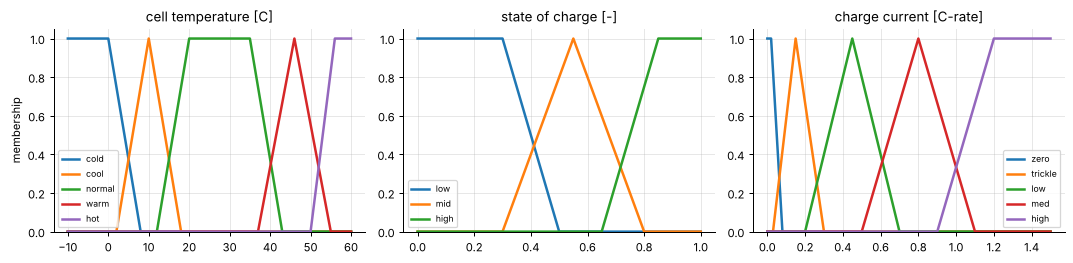

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for ax, (title, (u, sets)) in zip(axs, [("cell temperature [C]", TEMP),
                                        ("state of charge [-]", SOC),
                                        ("charge current [C-rate]", CURRENT)]):
    for lab, spec in sets.items():
        ax.plot(u, mf(u, spec), lw=2, label=lab)
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=7)
axs[0].set_ylabel("membership")
fig.tight_layout()
fig.savefig("figures/fuzzy_membership.png", dpi=150)
plt.show()

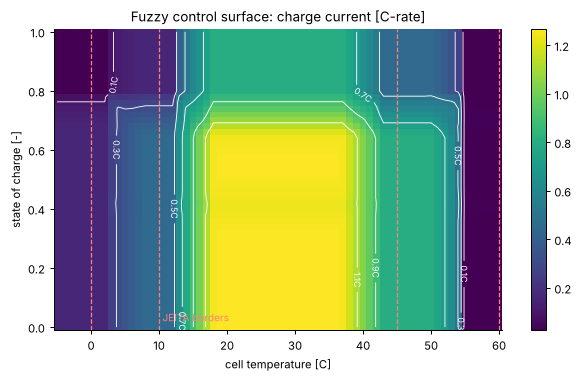

In [12]:
Tg = np.linspace(-5, 60, 66)
Sg = np.linspace(0, 1, 51)
Z = np.array([[fuzzy_current(T, s) for T in Tg] for s in Sg])
fig, ax = plt.subplots(figsize=(7, 4.3))
pm = ax.pcolormesh(Tg, Sg, Z, cmap="viridis", shading="auto")
cs = ax.contour(Tg, Sg, Z, levels=[0.1, 0.3, 0.5, 0.7, 0.9, 1.1], colors="w", linewidths=0.7)
ax.clabel(cs, fmt="%.1fC", fontsize=7)
for x in (0, 10, 45, 60):
    ax.axvline(x, color="#ff7f7f", ls="--", lw=1)
ax.text(10.5, 0.02, "JEITA borders", color="#ff7f7f", fontsize=8)
ax.set_xlabel("cell temperature [C]")
ax.set_ylabel("state of charge [-]")
ax.set_title("Fuzzy control surface: charge current [C-rate]")
ax.grid(False)
fig.colorbar(pm, ax=ax)
fig.tight_layout()
fig.savefig("figures/fuzzy_surface.png", dpi=150)
plt.show()

**Explanation of one decision.** The fuzzy system can explain itself too: the membership degrees and the strength of every fired rule.

In [13]:
_ = fuzzy_current(9.9, 0.45, verbose=True)
print()
_ = fuzzy_current(10.1, 0.45, verbose=True)

T = 9.9 C, SOC = 0.45  ->  I = 0.45 C
  T  : {'cool': 0.99}
  SOC: {'low': 0.25, 'mid': 0.6}
  strength 0.60: IF T is cool AND SOC is mid THEN I is low
  strength 0.25: IF T is cool AND SOC is low THEN I is low

T = 10.1 C, SOC = 0.45  ->  I = 0.45 C
  T  : {'cool': 0.99}
  SOC: {'low': 0.25, 'mid': 0.6}
  strength 0.60: IF T is cool AND SOC is mid THEN I is low
  strength 0.25: IF T is cool AND SOC is low THEN I is low


## 4. Simulation and comparison

### 4.1 Process model: one NMC 18650 cell, 3 Ah
* **Electrical:** a first-order equivalent circuit, `V = OCV(SOC) + v1 + I*R0`, with `dv1/dt = (I*R1 - v1)/tau1`. The resistances rise in the cold following an Arrhenius law (they are 2.7 times larger at 0 °C than at 25 °C).
* **Thermal:** a lumped model, `C_th dT/dt = I^2 R0 + v1^2/R1 - hA (T - T_amb)`. The cell sits inside a pack, so the cooling `hA` is weak and the cell time constant is about 20 minutes.
* **Degradation index (illustrative):** two mechanisms are integrated over the charge.
  * **SEI growth:** Arrhenius with `Ea = 50 kJ/mol`, weighted by current.
  * **Lithium plating:** proportional to `(I - I_lim)^2` when the current exceeds a plating limit `I_lim(T, SOC)`. That limit falls by a factor e for every 12 °C of cooling and also falls at high SOC.

  The shape follows the post-mortem study of Waldmann et al. (2014): ageing is lowest around 25 °C, plating dominates below that and SEI growth above. The **absolute values are not calibrated**. We report the index relative to a 1C CC-CV charge at 25 °C (= 1.0).

All controllers sit behind the same **BMS protection**: no current below 0 °C or above 60 °C, and a constant-voltage (CV) clamp, so the terminal voltage never exceeds the voltage limit. Every charge is a **fast charge to 80 % SOC**, the usual specification. It ends at 80 % SOC or after 3 hours.

In [14]:
Q_AH = 3.0                                   # rated capacity, Ah  (1C = 3 A)
SOC_PTS = np.array([0, .05, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1])
OCV_PTS = np.array([3.00, 3.30, 3.45, 3.55, 3.62, 3.68, 3.75, 3.84, 3.93, 4.02, 4.10, 4.20])
CELL = dict(R0=0.035, R1=0.020, tau1=40.0, EaR_res=3200.0,   # ohm, ohm, s, K
            Cth=45.0, hA=0.035,                              # J/K, W/K
            EaR_sei=50e3 / 8.314, k_pl=40.0)                  # K, plating weight
DT = 2.0                                     # s


def ocv(soc):
    return float(np.interp(soc, SOC_PTS, OCV_PTS))


class Cell:
    def __init__(self, soc0=0.2, T0=25.0, R_factor=1.0, hA_factor=1.0, Q_factor=1.0):
        self.soc, self.T, self.v1 = soc0, T0, 0.0
        self.Rf, self.hA, self.Q = R_factor, CELL["hA"] * hA_factor, Q_AH * Q_factor
        self.sei = self.plating = 0.0

    def _arr(self):                                    # resistance factor vs temperature
        return math.exp(CELL["EaR_res"] * (1 / (self.T + 273.15) - 1 / 298.15)) * self.Rf

    def r0(self):
        return CELL["R0"] * self._arr()

    def voltage(self, I):
        return ocv(self.soc) + self.v1 + I * self.r0()

    def max_current(self, v_lim):                      # CV clamp
        return max(0.0, (v_lim - ocv(self.soc) - self.v1) / self.r0())

    def step(self, I, T_amb, dt=DT):
        a = self._arr()
        R0, R1 = CELL["R0"] * a, CELL["R1"] * a
        self.v1 += dt * (I * R1 - self.v1) / CELL["tau1"]
        heat = I * I * R0 + self.v1 ** 2 / R1
        self.T += dt * (heat - self.hA * (self.T - T_amb)) / CELL["Cth"]
        self.soc = min(1.0, self.soc + I * dt / 3600 / self.Q)
        c_rate, h = I / Q_AH, dt / 3600
        self.sei += math.exp(CELL["EaR_sei"] * (1 / 298.15 - 1 / (self.T + 273.15))) * (0.2 + c_rate) * h
        i_lim = math.exp((self.T - 25) / 12) * (1.3 - 0.6 * self.soc)
        self.plating += CELL["k_pl"] * max(0.0, c_rate - i_lim) ** 2 * h

### 4.2 Controllers
1. **Baseline: CC-CV + on-off thermostat.** This is a simple charger: 1C constant current, then constant voltage at 4.20 V. It stops when the cell reaches 45 °C and restarts below 40 °C.
2. **JEITA step charger, the Part 1 rule base used as a controller.** At every step the measurements go through `sense()` and `forward_chain()`, and the derived mode sets the current and voltage limits. This is crisp rule-based control.
3. **Fuzzy charger (Part 3).** The current comes from the fuzzy surface, with a CV limit of 4.20 V.

In [15]:
class CCCVThermostat:
    name = "CC-CV + on-off"

    def __init__(self, i_c=1.0, t_off=45.0, t_on=40.0):
        self.i_c, self.t_off, self.t_on, self.on = i_c, t_off, t_on, True

    def __call__(self, m):
        if m["T"] >= self.t_off:
            self.on = False
        elif m["T"] <= self.t_on:
            self.on = True
        return (self.i_c if self.on else 0.0), 4.20


JEITA_LIMITS = {"charging forbidden": (0.0, 4.20),
                "mode: pre-charge (I <= 0.1C until V > 3.0 V)": (0.1, 4.20),
                "mode: cool charge (I <= 0.5C, V <= 4.20 V)": (0.5, 4.20),
                "mode: warm charge (I <= 1C, V <= 4.10 V)": (1.0, 4.10),
                "mode: standard charge (I <= 1C, V <= 4.20 V)": (1.0, 4.20)}


class JEITARuleCharger:
    name = "JEITA rules (crisp)"

    def __call__(self, m):
        facts, _ = forward_chain(sense({"T": m["T"], "V": m["V"], "dTdt": m["dTdt"],
                                        "SOH": 1.0, "R_ratio": 1.0, "spread": 0.0}), RULES)
        mode = next(d for d in MODE_PRIORITY if d in facts)
        return JEITA_LIMITS[mode]


class FuzzyCharger:
    name = "Fuzzy (Mamdani)"

    def __call__(self, m):
        i = fuzzy_current(m["T"], m["soc"])
        return (i if i >= 0.03 else 0.0), 4.20


CONTROLLERS = [CCCVThermostat, JEITARuleCharger, FuzzyCharger]
COLORS = {"CC-CV + on-off": "#c0504d", "JEITA rules (crisp)": "#e69f00", "Fuzzy (Mamdani)": "#1f5aa6"}

### 4.3 Simulation and measures
* **Error (charging goal not met):** the time to reach 80 % SOC, and the SOC still missing from the 80 % target after 30 minutes.
* **Effort:** the peak current and the heat dissipated in the cell (Wh).
* **Switching:** the number of times the charger stops and restarts, the number of current steps larger than 0.2C, and the total current travel `sum |dI|`.
* **Constraints and consequences:** the maximum cell temperature, the minutes above 45 °C, and the degradation index (1.0 = 1C CC-CV at 25 °C).

In [16]:
def simulate(ctrl, T_amb, soc0=0.2, max_min=180, soc_target=0.8, **cell_kw):
    cell = Cell(soc0, T_amb, **cell_kw)
    n = int(max_min * 60 / DT)
    log = {k: [] for k in ("t", "I", "T", "soc", "V")}
    I_prev, T_prev, heat = 0.0, cell.T, 0.0
    for k in range(n):
        m = {"T": cell.T, "soc": cell.soc, "V": cell.voltage(I_prev),
             "dTdt": (cell.T - T_prev) / DT * 60}
        T_prev = cell.T
        c_req, v_lim = ctrl(m)
        I = c_req * Q_AH
        if cell.T < 0 or cell.T >= 60:                      # BMS protection
            I = 0.0
        I = min(I, cell.max_current(v_lim))                 # CV clamp
        if cell.soc >= soc_target:                          # end of charge
            break
        heat += (I * I * cell.r0() + cell.v1 ** 2 / (CELL["R1"] * cell._arr())) * DT / 3600
        cell.step(I, T_amb)
        for key, val in zip(log, (k * DT / 60, I / Q_AH, cell.T, cell.soc, cell.voltage(I))):
            log[key].append(val)
        I_prev = I
    r = {k: np.array(v) for k, v in log.items()}
    r["heat_Wh"], r["sei"], r["plating"] = heat, cell.sei, cell.plating
    return r


def metrics(r, d_ref=1.0, max_min=180):
    t, I, soc = r["t"], r["I"], r["soc"]
    reach = np.nonzero(soc >= 0.8)[0]
    soc30 = soc[min(np.searchsorted(t, 30), len(soc) - 1)]
    stops = int(np.sum((I[1:] == 0) & (I[:-1] > 0)))
    return {"time_to_80_min": float(t[reach[0]]) if len(reach) else float(max_min),
            "soc_short_30min": float(max(0.0, 0.8 - soc30)),
            "peak_current_C": float(I.max()),
            "heat_Wh": float(r["heat_Wh"]),
            "stops": stops,
            "steps_gt_0.2C": int(np.sum(np.abs(np.diff(I)) > 0.2)),
            "current_travel_C": float(np.abs(np.diff(I)).sum()),
            "max_T_C": float(r["T"].max()),
            "min_above_45C": float(np.sum(r["T"] > 45) * DT / 60),
            "degradation": float((r["sei"] + r["plating"]) / d_ref)}


_ref = simulate(CCCVThermostat(), 25.0, 0.2)
D_REF = _ref["sei"] + _ref["plating"]
print(f"reference 1C CC-CV at 25 C: {metrics(_ref)['time_to_80_min']:.0f} min to 80 %, "
      f"SEI part {_ref['sei']:.3f}, plating part {_ref['plating']:.3f}  -> index 1.00")


def show_table(rows, keys=None):
    keys = keys or list(next(iter(rows.values())).keys())
    head = f"{'controller':22s}" + "".join(f"{k:>18s}" for k in keys)
    print(head)
    print("-" * len(head))
    for name, m in rows.items():
        print(f"{name:22s}" + "".join(f"{m[k]:18.2f}" if isinstance(m[k], float) else f"{m[k]:18d}"
                                      for k in keys))

reference 1C CC-CV at 25 C: 36 min to 80 %, SEI part 1.090, plating part 0.000  -> index 1.00


### 4.4 Three scenarios: cold, room and hot ambient (start at 20 % SOC)
At 25 °C the JEITA charger (dashed) is identical to CC-CV, because the cell stays in the standard zone.


### cold ambient 5 C
controller                time_to_80_min   soc_short_30min    peak_current_C           heat_Wh             stops     steps_gt_0.2C           max_T_C     min_above_45C       degradation
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
CC-CV + on-off                     36.03              0.10              1.00              0.42                 0                 0             20.23              0.00              6.51
JEITA rules (crisp)                51.53              0.35              1.00              0.36                 0                 1             18.84              0.00              5.39
Fuzzy (Mamdani)                    90.97              0.39              0.45              0.23                 0                 0              9.85              0.00              1.60

### room ambient 25 C
controller                time

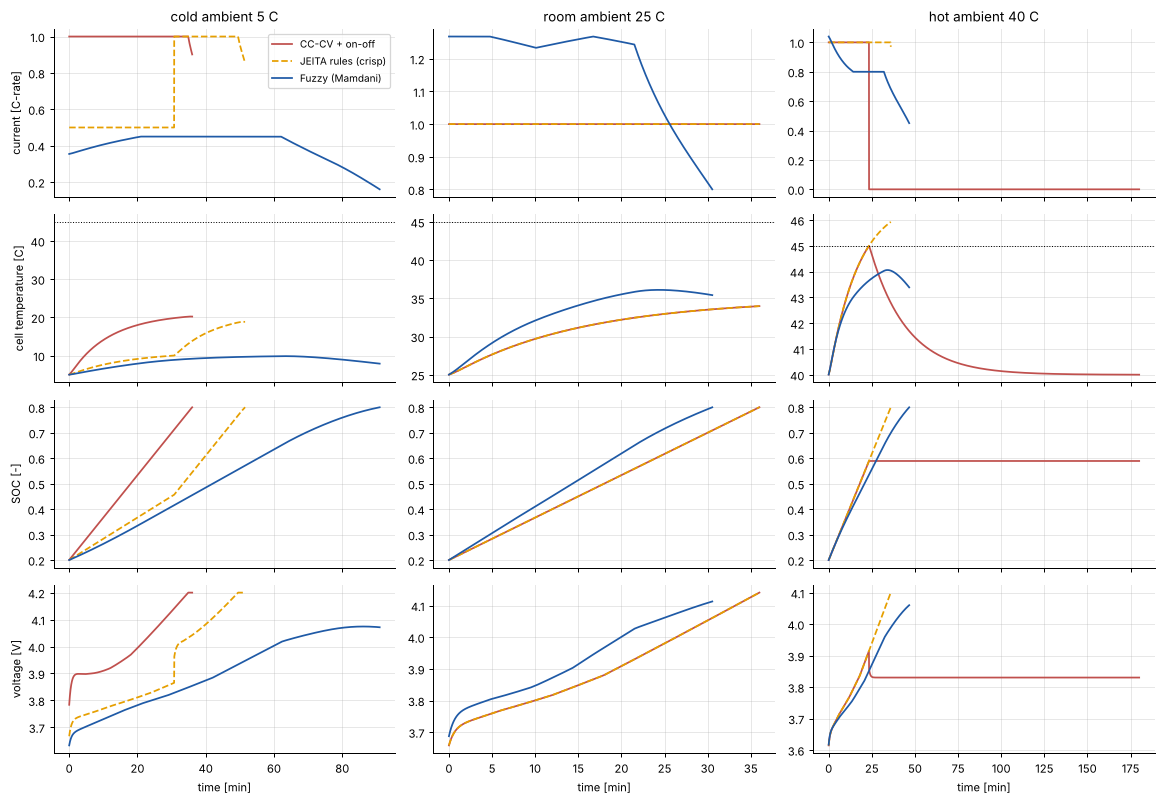

In [17]:
SCENARIOS = [("cold ambient 5 C", 5.0), ("room ambient 25 C", 25.0), ("hot ambient 40 C", 40.0)]
scenario_results = {}
fig, axs = plt.subplots(4, 3, figsize=(13, 9), sharex="col")
for col, (title, Ta) in enumerate(SCENARIOS):
    rows = {}
    for C in CONTROLLERS:
        r = simulate(C(), Ta, 0.2)
        rows[C.name] = metrics(r, D_REF)
        for row, key in enumerate(("I", "T", "soc", "V")):
            axs[row, col].plot(r["t"], r[key], color=COLORS[C.name], label=C.name, lw=1.4,
                               ls="--" if C is JEITARuleCharger else "-")
    scenario_results[title] = rows
    axs[0, col].set_title(title)
    axs[1, col].axhline(45, color="k", ls=":", lw=0.8)
    axs[3, col].set_xlabel("time [min]")
    print(f"\n### {title}")
    show_table(rows, ["time_to_80_min", "soc_short_30min", "peak_current_C", "heat_Wh",
                      "stops", "steps_gt_0.2C", "max_T_C", "min_above_45C", "degradation"])
for row, lab in enumerate(("current [C-rate]", "cell temperature [C]", "SOC [-]", "voltage [V]")):
    axs[row, 0].set_ylabel(lab)
axs[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig("figures/scenarios_time_response.png", dpi=150)
plt.show()

### 4.5 Operating range: ambient from 0 to 44 °C

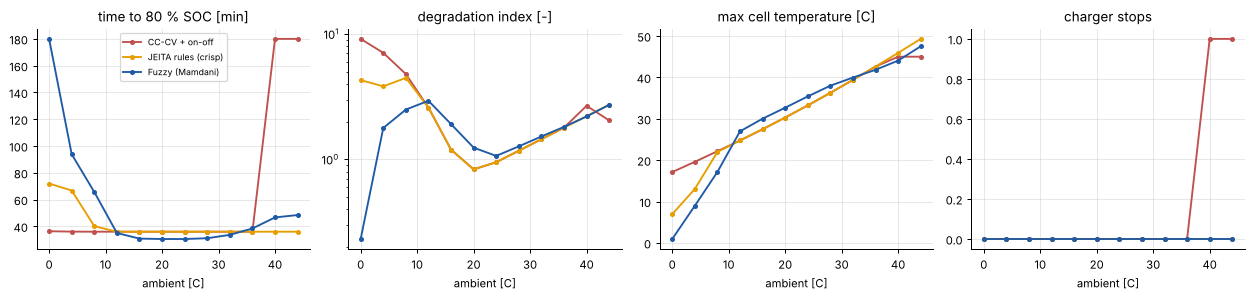

In [18]:
amb_grid = np.arange(0, 45, 4.0)
sweep = {C.name: [metrics(simulate(C(), Ta, 0.2), D_REF) for Ta in amb_grid] for C in CONTROLLERS}
fig, axs = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, key, lab in zip(axs, ("time_to_80_min", "degradation", "max_T_C", "stops"),
                        ("time to 80 % SOC [min]", "degradation index [-]",
                         "max cell temperature [C]", "charger stops")):
    for name, ms in sweep.items():
        ax.plot(amb_grid, [m[key] for m in ms], "o-", ms=3, color=COLORS[name], label=name)
    ax.set_xlabel("ambient [C]")
    ax.set_title(lab)
axs[1].set_yscale("log")
axs[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig("figures/operating_range.png", dpi=150)
plt.show()

### 4.6 Ten random charging situations (seeds 0-9)
Each seed draws an ambient temperature (0-42 °C), a starting SOC (5-40 %) and a cell that is not exactly nominal: resistance x0.8-1.3, cooling x0.8-1.2, capacity x0.95-1.05. All three controllers charge **the same** ten cells.

mean +/- std over 10 seeds

CC-CV + on-off
   time_to_80_min          47.01 +/-  43.80
   soc_short_30min          0.11 +/-   0.11
   heat_Wh                  0.26 +/-   0.12
   stops                    0.20 +/-   0.63
   steps_gt_0.2C            0.40 +/-   1.26
   current_travel_C         0.43 +/-   1.26
   max_T_C                 33.39 +/-   8.13
   min_above_45C            0.02 +/-   0.05
   degradation              2.03 +/-   1.58

JEITA rules (crisp)
   time_to_80_min          35.48 +/-  10.50
   soc_short_30min          0.11 +/-   0.13
   heat_Wh                  0.25 +/-   0.10
   stops                    2.10 +/-   6.64
   steps_gt_0.2C            4.30 +/-  13.25
   current_travel_C         4.30 +/-  13.25
   max_T_C                 33.44 +/-   8.93
   min_above_45C            1.91 +/-   6.04
   degradation              1.86 +/-   1.30

Fuzzy (Mamdani)
   time_to_80_min          38.93 +/-  22.86
   soc_short_30min          0.11 +/-   0.15
   heat_Wh                  0.25 +/-   

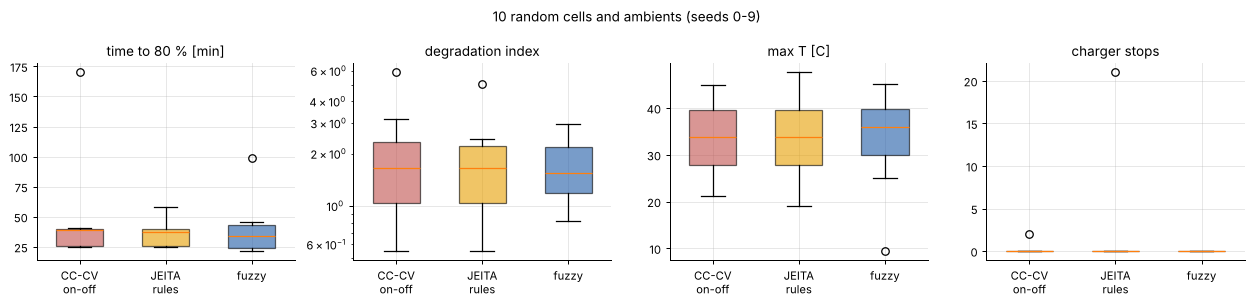

In [19]:
seed_rows = []
for seed in range(10):
    rng = np.random.default_rng(seed)
    case = dict(T_amb=rng.uniform(0, 42), soc0=rng.uniform(0.05, 0.4),
                R_factor=rng.uniform(0.8, 1.3), hA_factor=rng.uniform(0.8, 1.2),
                Q_factor=rng.uniform(0.95, 1.05))
    for C in CONTROLLERS:
        m = metrics(simulate(C(), **case), D_REF)
        seed_rows.append({"seed": seed, "controller": C.name, **case, **m})

KEYS = ["time_to_80_min", "soc_short_30min", "heat_Wh", "stops", "steps_gt_0.2C",
        "current_travel_C", "max_T_C", "min_above_45C", "degradation"]
print(f"{'mean +/- std over 10 seeds':22s}")
for C in CONTROLLERS:
    rr = [r for r in seed_rows if r["controller"] == C.name]
    print(f"\n{C.name}")
    for k in KEYS:
        v = np.array([r[k] for r in rr], dtype=float)
        print(f"   {k:20s} {v.mean():8.2f} +/- {v.std(ddof=1):6.2f}")

fig, axs = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, key, lab in zip(axs, ("time_to_80_min", "degradation", "max_T_C", "stops"),
                        ("time to 80 % [min]", "degradation index", "max T [C]", "charger stops")):
    data = [[r[key] for r in seed_rows if r["controller"] == C.name] for C in CONTROLLERS]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55)
    for patch, C in zip(bp["boxes"], CONTROLLERS):
        patch.set_facecolor(COLORS[C.name])
        patch.set_alpha(0.6)
    ax.set_xticks([1, 2, 3], ["CC-CV\non-off", "JEITA\nrules", "fuzzy"])
    ax.set_title(lab)
axs[1].set_yscale("log")
fig.suptitle("10 random cells and ambients (seeds 0-9)")
fig.tight_layout()
fig.savefig("figures/seeds_boxplot.png", dpi=150)
plt.show()

In [20]:
# paired comparison: fuzzy vs each baseline on the same seed
def paired(a, b, key):
    A = {r["seed"]: r[key] for r in seed_rows if r["controller"] == a}
    B = {r["seed"]: r[key] for r in seed_rows if r["controller"] == b}
    return np.array([A[s] - B[s] for s in range(10)])

for base in ("CC-CV + on-off", "JEITA rules (crisp)"):
    print(f"\nFuzzy minus {base} (negative = fuzzy lower):")
    for k in ("time_to_80_min", "degradation", "max_T_C", "stops", "steps_gt_0.2C"):
        d = paired("Fuzzy (Mamdani)", base, k)
        print(f"   {k:16s} mean {d.mean():+8.2f}   min {d.min():+8.2f}   max {d.max():+8.2f}"
              f"   fuzzy better in {np.sum(d < 0)}/10, equal in {np.sum(d == 0)}/10")


Fuzzy minus CC-CV + on-off (negative = fuzzy lower):
   time_to_80_min   mean    -8.08   min  -124.87   max   +60.13   fuzzy better in 7/10, equal in 0/10
   degradation      mean    -0.36   min    -4.14   max    +0.52   fuzzy better in 2/10, equal in 0/10
   max_T_C          mean    -0.20   min   -11.70   max    +2.58   fuzzy better in 3/10, equal in 0/10
   stops            mean    -0.20   min    -2.00   max    +0.00   fuzzy better in 1/10, equal in 9/10
   steps_gt_0.2C    mean    -0.40   min    -4.00   max    +0.00   fuzzy better in 1/10, equal in 9/10

Fuzzy minus JEITA rules (crisp) (negative = fuzzy lower):
   time_to_80_min   mean    +3.45   min    -6.30   max   +40.87   fuzzy better in 7/10, equal in 0/10
   degradation      mean    -0.19   min    -3.27   max    +0.52   fuzzy better in 2/10, equal in 0/10
   max_T_C          mean    -0.25   min    -9.61   max    +2.60   fuzzy better in 4/10, equal in 0/10
   stops            mean    -2.10   min   -21.00   max    +0.00   fuzzy

### 4.7 Speed versus ageing: is the comparison fair?
A controller can always charge more gently, and so age the cell less, at the cost of a slower charge. To compare the *control laws* rather than one current level, every controller is run with its current scaled by g = 0.6 ... 1.4 on the same ten seeds. A curve that lies further down and to the left is better.

CC-CV + on-off         x0.6:  55.7 min / 1.34  x0.8:  48.6 min / 1.68  x1.0:  47.0 min / 2.03  x1.2:  44.8 min / 2.35  x1.4:  43.0 min / 2.63
JEITA rules (crisp)    x0.6:  62.1 min / 1.07  x0.8:  46.6 min / 1.32  x1.0:  35.5 min / 1.86  x1.2:  29.8 min / 2.34  x1.4:  27.0 min / 2.96
Fuzzy (Mamdani)        x0.6:  65.8 min / 1.05  x0.8:  49.1 min / 1.31  x1.0:  38.9 min / 1.67  x1.2:  32.9 min / 2.09  x1.4:  26.8 min / 2.83


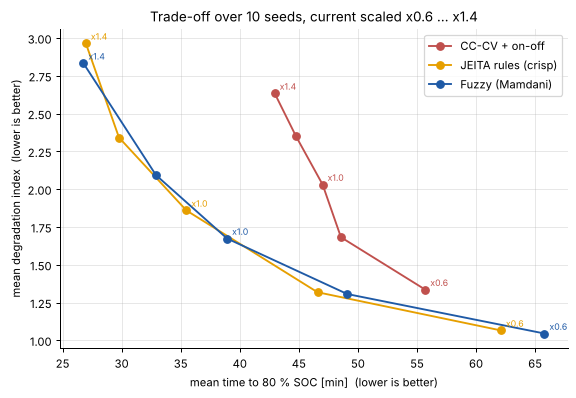

In [21]:
class Scaled:
    def __init__(self, C, g):
        self.c, self.g = C(), g

    def __call__(self, m):
        i, v = self.c(m)
        return i * self.g, v


SEED_CASES = []
for seed in range(10):
    rng = np.random.default_rng(seed)
    SEED_CASES.append(dict(T_amb=rng.uniform(0, 42), soc0=rng.uniform(0.05, 0.4),
                           R_factor=rng.uniform(0.8, 1.3), hA_factor=rng.uniform(0.8, 1.2),
                           Q_factor=rng.uniform(0.95, 1.05)))
GAINS = (0.6, 0.8, 1.0, 1.2, 1.4)
tradeoff = {}
for C in CONTROLLERS:
    pts = []
    for g in GAINS:
        ms = [metrics(simulate(Scaled(C, g), **case), D_REF) for case in SEED_CASES]
        pts.append((g, np.mean([m["time_to_80_min"] for m in ms]),
                    np.mean([m["degradation"] for m in ms])))
    tradeoff[C.name] = pts

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, pts in tradeoff.items():
    _, t, d = zip(*pts)
    ax.plot(t, d, "o-", color=COLORS[name], label=name)
    for g, ti, di in pts:
        if g in (0.6, 1.0, 1.4):
            ax.annotate(f"x{g}", (ti, di), xytext=(4, 3), textcoords="offset points",
                        fontsize=7, color=COLORS[name])
ax.set_xlabel("mean time to 80 % SOC [min]  (lower is better)")
ax.set_ylabel("mean degradation index  (lower is better)")
ax.set_title("Trade-off over 10 seeds, current scaled x0.6 ... x1.4")
ax.legend()
fig.tight_layout()
fig.savefig("figures/tradeoff_speed_vs_ageing.png", dpi=150)
plt.show()
for name, pts in tradeoff.items():
    print(f"{name:22s}", "  ".join(f"x{g}: {t:5.1f} min / {d:4.2f}" for g, t, d in pts))

### 4.8 A brittle rule caught in simulation
In seed 2 (ambient 11 °C, a cell with 21 % higher resistance) the JEITA rule charger stops 21 times. Starting at 1C, ordinary Joule heating warms this cell by more than 1 °C/min. Rule R4 reads that as *abnormal self-heating* and forbids charging. The cell then cools, charging restarts, and the cycle repeats. A heuristic threshold that seemed safe on paper produces false alarms and chattering on a real operating point. The fuzzy charger is not subject to R4 and runs smoothly. Note that its own heating rate also passes 1 °C/min around minute 14, so if R4 were a pack-wide protection, it would trip the fuzzy charger too. The fault is in the threshold, not in the charger.

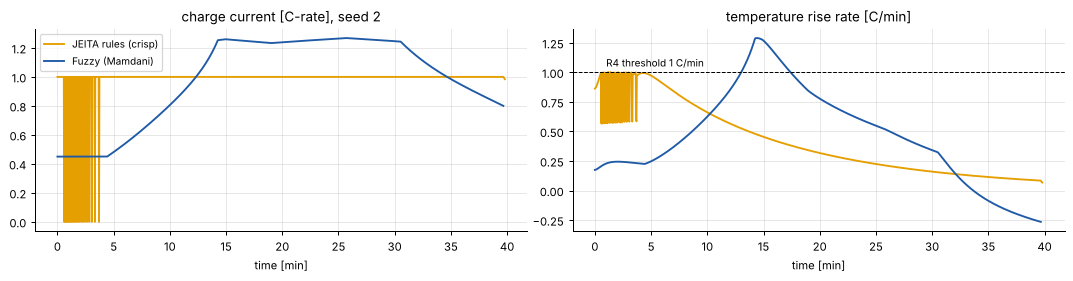

In [22]:
case = SEED_CASES[2]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.2))
for C in (JEITARuleCharger, FuzzyCharger):
    r = simulate(C(), **case)
    dTdt = np.gradient(r["T"], r["t"])
    axs[0].plot(r["t"], r["I"], color=COLORS[C.name], label=C.name)
    axs[1].plot(r["t"], dTdt, color=COLORS[C.name])
axs[1].axhline(1.0, color="k", ls="--", lw=0.8)
axs[1].text(1, 1.05, "R4 threshold 1 C/min", fontsize=8)
axs[0].set_title("charge current [C-rate], seed 2")
axs[1].set_title("temperature rise rate [C/min]")
axs[0].legend(fontsize=8)
for ax in axs:
    ax.set_xlabel("time [min]")
fig.tight_layout()
fig.savefig("figures/jeita_chattering_seed2.png", dpi=150)
plt.show()

### 4.9 Summary of the results

**Ten random cells (seeds 0-9), mean values:**

| | CC-CV + on-off | JEITA rules (crisp) | Fuzzy (Mamdani) |
|---|---|---|---|
| time to 80 % SOC [min] | 47.0 | **35.5** | 38.9 |
| degradation index | 2.03 | 1.86 | **1.67** |
| charger stops | 0.2 | 2.1 | **0** |
| current steps > 0.2C | 0.4 | 4.3 | **0** |

* **Read the mean degradation with care.** The fuzzy charger's lower mean comes mostly from the one cold seed (seed 3, 3.6 °C), where it avoids heavy plating. In 8 of the 10 seeds it ages the cell slightly *more* than JEITA (at most +0.52), because it charges harder at room temperature.
* **Cold (5 °C):** the fuzzy charger keeps the current under the plating limit. Its degradation index is about 4 times lower than the other two (1.6 vs 6.5 and 5.4), but it needs 91 minutes instead of 36-52. The JEITA cool zone (0.5C) still plates lithium in this model.
* **Operating range (4.5):** the fuzzy charger is too cautious at the cold end. At 0 °C ambient it only trickles (about 0.15C) and does **not** reach 80 % within 3 hours, while JEITA needs 72 minutes. Between 12 and 32 °C it is the fastest of the three. Above 36 °C the thermostat stops for good.
* **Room (25 °C):** the fuzzy charger is faster (31 vs 36 min) because it uses up to 1.27C at low SOC, which costs about 10 % more degradation.
* **Hot (40 °C):** the on-off thermostat **deadlocks**. It stops at 45 °C and waits for 40 °C, which the cell can never reach in a 40 °C ambient, so the charge never finishes. JEITA keeps charging at 1C in its warm zone and spends 13 minutes above 45 °C. The fuzzy charger never exceeds 45 °C, for about the same degradation and 11 minutes more.
* **Trade-off (4.7):** when all three controllers are scaled from gentle to aggressive, the fuzzy curve and the JEITA curve almost coincide, and both lie well below the CC-CV + on-off curve. The honest conclusion: **with the same knowledge, the fuzzy controller does not charge faster for the same ageing. Its gain is smoothness**, with no stops, no current steps, no chattering and no cliff at 10 °C.

## 5. Discussion

**Where are the rules brittle?**
* **Crisp thresholds create cliffs.** At 9.9 °C the allowed current is 0.5C, at 10.1 °C it is 1C (test case 3). The same happens at SOH 79.9 % vs 80.1 %. A sensor error of 0.2 °C changes the decision.
* **Heuristic thresholds can be wrong for the operating point.** The 1 °C/min self-heating rule (R4) fires on ordinary Joule heating of a cool, slightly resistive cell at 1C. In simulation it produced 21 false stops (4.8). Real thermal-runaway onsets are much faster, so the threshold should be reviewed, made dependent on the current, or combined with a second symptom such as a voltage drop or gas venting.
* **Missing hysteresis.** The rule charger switches mode every time T crosses a border. The baseline thermostat has hysteresis, but its lower set point (40 °C) is not reachable in a hot ambient, which causes the deadlock in 4.4.
* **Gaps and conflicts.** The first version of the rule base derived no charge mode at all for a deep-discharged cell between 45 and 60 °C. The decision map revealed this gap, and rule R15 was added. Conflicts, such as a warm-charge mode plus a fault, are resolved by a fixed priority list (`MODE_PRIORITY`). That list is knowledge too, and it must be reviewed.
* **Closed-world sensing.** Negations such as `dT/dt <= 1 C/min` are produced by `sense()`. A missing or failed sensor would silently look like "normal". A real BMS needs plausibility rules for its sensors.

**How would an expert review them?**
1. Trace each rule to its source (the `source` field) and check the numbers against the actual cell datasheet. Charger ICs implement JEITA with different T1-T4 and current values.
2. The chemical engineer reviews the electrochemical rationale: the plating limit versus temperature and SOC, SEI growth, and safe pre-charge conditions.
3. Walk through the decision map and the borderline cases with a battery engineer, and add hysteresis where a border is crossed often.
4. Run the rule base on logged BMS data and on abuse-test records. Count false alarms (like R4) and missed faults, and keep a list of cases where the expert disagrees with the system.

**What would a learned model add or lose?**
* **Add:** a model trained on cycling data could learn the real plating limit and ageing rate of this specific cell. That would replace our illustrative degradation index. Optimisation or reinforcement learning on such a model could find charge profiles that are *both* faster and gentler, which neither hand-written controller achieves here (4.7). A learned anomaly detector could also replace the fixed 1 °C/min rule.
* **Lose:** the rule base can cite IEC 62133-2 and JEITA for every decision, which matters for safety certification. A neural network cannot. A learned model can fail silently outside its training data, for example on a new cell chemistry or an unseen temperature. It needs large, expensive ageing datasets. A sensible design keeps the rule base as a **safety envelope** and lets a learned or fuzzy controller optimise *inside* it, as our BMS protection layer already does.

**Limitations of this study.** The degradation model is semi-empirical and uncalibrated (only its trend follows the literature). The cell is a single lumped thermal mass. SOC is assumed to be known exactly. Results in absolute minutes and index values should not be quoted as properties of a real cell.

## References
1. JEITA & BAJ, *A Guide to the Safe Use of Secondary Lithium Ion Batteries in Notebook-type Personal Computers*, 2007.
2. IEC 62133-2:2017, *Secondary cells and batteries containing alkaline or other non-acid electrolytes: safety requirements for portable sealed secondary lithium cells*.
3. T. Waldmann, M. Wilka, M. Kasper, M. Fleischhammer, M. Wohlfahrt-Mehrens, "Temperature dependent ageing mechanisms in lithium-ion batteries: a post-mortem study," *Journal of Power Sources* 262 (2014) 129-135.
4. E. H. Mamdani and S. Assilian, "An experiment in linguistic synthesis with a fuzzy logic controller," *Int. J. Man-Machine Studies* 7(1), 1975.
5. G. L. Plett, *Battery Management Systems, Vol. 1: Battery Modeling*, Artech House, 2015 (equivalent circuit models).